# Retail Sales - Machine Learning

## Business Requirement 4

### Business Question

How effectively can machine learning models predict weekly department sales using historical sales patterns, store characteristics, and macro-economic factors, and what machine learning model is the optimal choice for this analysis?

This notebook implements and compares two predictive machine learning models to forecast weekly retail sales.

The goal of this analysis is to assis the retail manager in evaluating how accurately they can predict future sales using existing data.

### Machine Learning Concept 

- **Supervised Learning:**
  - a Machine Learning approach where a model uses labeled known data to make accurate predictions on a new data. 
- **Regression:** a machine learning method that looks at past data to predict exact numbers. In this case weekly sales.
- **Features (X):** The input data that is been fed into the data to make predictions, such as store size, store department and holiday status.
- **Target:(y)** The output data that you want the model to predict, such as 'Weekly sales' for this project.
- **Training Data:** The dataset contaning the feautures X and target y used to train the machine learning model. This model makes prediions on new data. 
- **Test Data:** A later observation used to asses how well the model performs on an unseen data.
- **Overfitting:** Describes when a model learns too much from the training data memorizing random noise and quirks instead of the general pattern. Performs well on training data but not on test data. 

### Models Chosen

**1. Linear Regression**

A simple regression model that makes an estimation on sales, by using linear relationships between the features (X) and the target (y). 

**2. Random Forest Regression** 

A model that links together several decision trees to spot more complicated patterns that a single tree might miss.

### Evaluation Metrics

- **MAE (Mean absolute Error): Is the average absolute difference between the predicted and actual values.

- **RMSE (Root Mean Squared Error):** Measures the average size of prediction errors, with larger mistakes giving more weight.

- **R² (R-squared):** showes the amount of variation in sales that is explained by the model.

The same test data will be used to ensure a fair comparison.

### Expected Outcome

Compare both models to identify which achieves much better accuracy on unseen data. In addition to give an explanation of how these findings could support retail planning.

The main focus of this analysis is historical sales predictions rather than real-time forecasting.



In [1]:
import pandas as pd
from pathlib import Path

# Find the project folder
project_root = Path.cwd()

if not (project_root / "data").exists():
    project_root = project_root.parent

# Load the cleaned retail dataset
file_path = project_root / "data" / "cleaned" / "retail_sales_cleaned.csv"

df = pd.read_csv(file_path, parse_dates=["Date"])

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (421570, 22)


,Store,Dept,Date,Weekly_Sales,IsHoliday,Year,Month,Week,Temperature,Fuel_Price,...,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Markdown_Data_Available,Total_MarkDown,Type,Size,Markdown_Activity
0,1,1,2010-02-05,24924.50,False,2010,2,5,42.31,2.572,...,NaN,NaN,NaN,211.096358,8.106,False,NaN,A,151315,NaN
1,1,1,2010-02-12,46039.49,True,2010,2,6,38.51,2.548,...,NaN,NaN,NaN,211.242170,8.106,False,NaN,A,151315,NaN
2,1,1,2010-02-19,41595.55,False,2010,2,7,39.93,2.514,...,NaN,NaN,NaN,211.289143,8.106,False,NaN,A,151315,NaN
3,1,1,2010-02-26,19403.54,False,2010,2,8,46.63,2.561,...,NaN,NaN,NaN,211.319643,8.106,False,NaN,A,151315,NaN
4,1,1,2010-03-05,21827.90,False,2010,3,9,46.50,2.625,...,NaN,NaN,NaN,211.350143,8.106,False,NaN,A,151315,NaN


### Choosing Features and Target

Because we are forecasting a continuous numerical value from past observations, this problem falls under supervised regression.

**Target (y):**
- 'Weekly_Sales — the department's weekly sales value.

**Features (X):**
- Store and department identifiers
- Store type and size
- Holiday status
- Temperature and fuel price
- CPI and unemployment
- Month and week of the year
- Recorded markdown amounts

These features were chosen because they are associated with sales, as they describe store charcteristics, seasonal patterns and external factors.

the 'Date' column will be used when separating training and testing data, chronologically.

Any missing markdown values in the dataset will be addressed during the data preprocessing part.

In [2]:
# Select the information used to predict sales
features = [
    "Store",
    "Dept",
    "Type",
    "Size",
    "IsHoliday",
    "Temperature",
    "Fuel_Price",
    "CPI",
    "Unemployment",
    "Month",
    "Week",
    "Total_MarkDown"
]

# X contains the prediction features
X = df[features]

# y contains the value we want to predict
y = df["Weekly_Sales"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

X.head()

Features shape: (421570, 12)
Target shape: (421570,)


,Store,Dept,Type,Size,IsHoliday,Temperature,Fuel_Price,CPI,Unemployment,Month,Week,Total_MarkDown
0,1,1,A,151315,False,42.31,2.572,211.096358,8.106,2,5,NaN
1,1,1,A,151315,True,38.51,2.548,211.242170,8.106,2,6,NaN
2,1,1,A,151315,False,39.93,2.514,211.289143,8.106,2,7,NaN
3,1,1,A,151315,False,46.63,2.561,211.319643,8.106,2,8,NaN
4,1,1,A,151315,False,46.50,2.625,211.350143,8.106,3,9,NaN


## Training and Testing Data

The dataset will be split chronologically:

- **Training set (80% of dates):** Utilised to train machine learning models.
- **Test set (20% of dates):** Used to check how well the models perform on future, unseen weeks.

A chronological split is used instead of a random split, to ensure the model does not accidentally learn from future weeks, during training.

Both Linear Reggression and Random Forest will use the same train and test period, to ensure fairness. 

In [ ]:
# Organise the unique dates into chronological order
dates = sorted(df["Date"].unique())

# Find the date where the test period begins
split_index = int(len(dates) * 0.8)
split_date = dates[split_index]

# Create training and testing masks
train_mask = df["Date"] < split_date
test_mask = df["Date"] >= split_date

# Divide features and target
X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Test period begins:", pd.Timestamp(split_date).date())

Training rows: 335761
Testing rows: 85809
Test period begins: 2012-04-13


### Data Preprocessing 

The input features must be prepared, before training the models. 

- **Missing Values:** The median calculated from the training data will take the place of numerical missing values.

- **Categorical encoding:** one-hot encoding will used to convert store, department, and store type into numerical indicators.

- **Data Leakeage Prevention:** Preprocessing will be fitted exclusively on training data then applied to test data. 

A preprocessing pipeline ensures consistent prepared data.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Give a definition of categorical and numerical features
categorical_features = ["Store", "Dept", "Type"]

numerical_features = [
    "Size",
    "IsHoliday",
    "Temperature",
    "Fuel_Price",
    "CPI",
    "Unemployment",
    "Month",
    "Week",
    "Total_MarkDown"
]

# Replace missing numerical values with the training median
numerical_transformer = SimpleImputer(strategy="median")

# Convert categories into numerical indicators
categorical_transformer = OneHotEncoder(handle_unknown="ignore")

# Combine both preprocessing methods
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


## Model 1 - Linear Regression

Linear Regression serves as baseline model for predicting weekly department sales in this analysis.

This model captures the relationship between the chosen features and historical sales data.

The model will use a pipeline that first prepares the data and then trains the regression model.

The models predictions will be asses using the test dataset. Which contains the later weeks that were excluded from the training. 

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline


In [7]:
# Create the pipeline for Linear Regression

linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Use historical sales data to train the model
linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


## Model 2 - Random Forest Regression

Random Forest Regression puts together preditions from numerous decision trees.

This model can capture more complex, non-linear relationship between store characteristics, seasonal effects as well as weekly sales, unlike Linear Regression.

The model will use 30 trees with a maxium depth of 12, to manage training time.

Both Linear Regression and Random Forest will be assessed using the same test dataset, so that their predictive performance can be compared.


In [8]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.base import clone

In [10]:
# Create the pipeline for Random Forest Regressor
random_forest_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("regressor", RandomForestRegressor(n_estimators=30,
    max_depth=12, min_samples_leaf=5, random_state=42,
    n_jobs=-1))
])

# Give training the model using historical sales data
random_forest_model.fit(X_train, y_train)
print("Random Forest model trained successfully.")

Random Forest model trained successfully.


## Model Assessment And Comparison

The same test dataset with be used to evaluate both models.

The three performance metrics that will be compared are:

- **MAE (Mean Absolute Error):** Shows the average size of the errors made by the model. Lower means better.

- **RMSE (Root Mean Squared Error):** Measures prediction errors but gives a harsher penalty for bigger mistakes, however lower is better.

- **R² (R-squared):** Measures how well the model explains variations in weekly sales. Higher value is better, with 1 indicating a perfect prediction.

Doing a comparison of both models on unseen data shows us which model has better performance. 

In [11]:
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [12]:
# Use the test data to make predictions of weekly sales
linear_predictions = linear_model.predict(X_test)
random_forest_predictions = random_forest_model.predict(X_test)

# Calculate the evaluation metrics for both models
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, linear_predictions),
        mean_absolute_error(y_test, random_forest_predictions)
    ],
    "MSE": [
        np.sqrt(mean_squared_error(y_test, linear_predictions)),
        np.sqrt(mean_squared_error(y_test, random_forest_predictions))
    ],
    "R²": [
        r2_score(y_test, linear_predictions),
        r2_score(y_test, random_forest_predictions)
    ]
})

results.round(3)

,Model,MAE,MSE,R²
0,Linear Regression,8767.618,12894.368,0.655
1,Random Forest,7767.691,10696.665,0.763


#### Model Evaluation Findings

Random Forest Regression outperformed Linear Regression when it came to all three evaluation metrics.

- **MAE:** Random Forest achieved 7,767.691 (lower error) unlike Linear Regression which recieved 8,767.618.
- **RMSE:** Random Forest recorded 10,696.665 (lower error) in comparison to Linear regression with 12,894.368.
- **R²:** Random Forest atained 0.763 compared with 0.655 for Linear Regression.

Compared to Linear Regression, the Random Forest model lowered the average absolute prediction error by roughly 11.4% while accounting for 76.3% of the variation in the weekly department sales.

**Business Interpretations:** Random Forest Regression is the better choice for estimating weekly department sales. Unlike Linear Regression, this model delivered more accurate predictions on the unseen test period. 

However, prediction errors are still quite large and Random Forest Regression has only been tested on one chronological test period. Therefore, there is no guarantee that it will be able to perform as well in the future.


### Actual Versus Forecasted Weekly Sales

The scatter plot being applied, makes a comparison between actual weekly sales and the values forecasted by the Random Forest model. 

Each point represents a single test-set observation.

On the scatter plot the diagonal reference line marks perfect predictions, where predicted sales match actual sales.

If the points are closee to the line that means the predictions are more accurate, and if they are further away that indicates larger prediction errors.

A sample of 2,000 test observations is displayed so that the chart is easy to read.

In [13]:
import matplotlib.pyplot as plt
import numpy as np

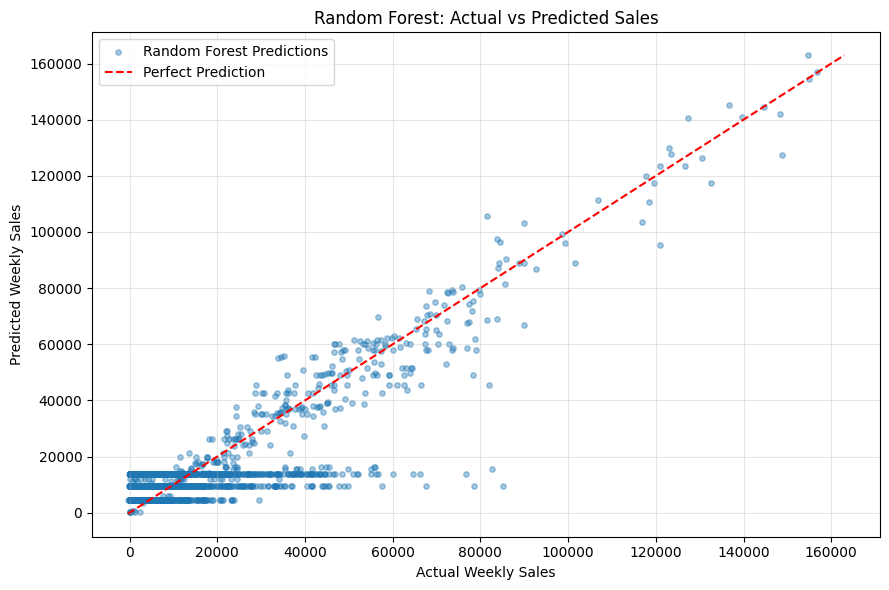

In [17]:
# Select a reproducible sample of 2,000 test observations
rng = np.random.default_rng(42)

test_sample_indices = rng.choice(
    len(y_test),
    size=min(2000, len(y_test)),
    replace=False
)

actual_sales = y_test.iloc[test_sample_indices]
predicted_sales = random_forest_predictions[test_sample_indices]

# Create scatter plot
plt.figure(figsize=(9, 6))

plt.scatter(
    actual_sales,
    predicted_sales,
    alpha=0.4,
    s=15,
    label="Random Forest Predictions"
)

# Add perfect prediction line
min_sales = min(actual_sales.min(), predicted_sales.min())
max_sales = max(actual_sales.max(), predicted_sales.max())

plt.plot(
    [min_sales, max_sales],
    [min_sales, max_sales],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Weekly Sales")
plt.ylabel("Predicted Weekly Sales")
plt.title("Random Forest: Actual vs Predicted Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### Business Requirement 4 - Conclusion

The aim of this analysis was to forecast weekly department sales, by utilizing, historical sales patterns, store characterstics as well as economic factors.

To make this analysis, two machine learning models were trained and evaluated. 

The model used were Linear Regression and Random Forest Regression.

### Key Findings:

Random Forest outperformed across all three evaluation metrics:

- **MAE:** Random Forest output 7,767.691 compared to Linear Regression (8,767.618).
- **RMSE:** 10,696.665 for Random Forest and 12,894.368 for Linear Regression.
- **R²:** 0.763 unlike 0.655 for Linear Regression.

Random Forest decreased the average absolute prediction error by roughly 11.4%.

The actual vs predicted sales scatter plot shows that many predictions align with expected sales trend, although some observations exhibit notable forecast errors.

### Business Recommendations:

For estimation of weekly department sales, Random Forest model is preffered.

The model's predictions could support inventory planning, staffing decisions as well as sales analysis. However it should be used alongside business judgement rather than treated as precise forecasts. 

### Constraints:

- The model still makes significant prediction errors.
- Results are based entirely on one chronological train-test split.
- Missing markdown values were replaced using the training set median.
- Some inputs, such as same-week economic conditions and markdown amounts, may not be available before the sales week begins. Because of this, the model isn't suited for forward-looking predictions, functioning more as a tool for historical estimation.

### Final Outcome:

To fullfill business requirement 4, two machine learning models were developed and compared. Random Forest Regression was chosen out of the two as it outperformed Linear Regression when it came to predicting on unseen test data. 